# Phase 02 - Machine Learning Experiments

## Objective

The objective of this experiment is to develop and compare multiple machine learning regression models for predicting Employability using Competence indicators.

The Competence variables (C1-C10) are used as predictive features, while EVS_avg is used as the target variable.

Different feature representations and machine learning algorithms are evaluated to identify the most suitable approach for Employability prediction.

In [50]:
from pathlib import Path

import pandas as pd
import numpy as np

import matplotlib.pyplot as plt

from sklearn.model_selection import (
    train_test_split,
    cross_val_score,
    KFold
)

from sklearn.preprocessing import StandardScaler

from sklearn.pipeline import Pipeline

from sklearn.linear_model import LinearRegression

from sklearn.ensemble import RandomForestRegressor

from sklearn.svm import SVR

from xgboost import XGBRegressor


from sklearn.metrics import (
    r2_score,
    mean_absolute_error,
    mean_squared_error
)

## Load Feature Engineered Dataset

The final feature engineered dataset created in the previous step is used for machine learning experiments.

In [51]:
PROJECT_DIR = Path.cwd()

if PROJECT_DIR.name == "phase2_competence":
    PROJECT_DIR = PROJECT_DIR.parent.parent


DATA_PATH = (
    PROJECT_DIR
    /
    "data"
    /
    "processed"
    /
    "phase2_competence_ml_features.csv"
)


df = pd.read_csv(DATA_PATH)


print("Dataset Shape:", df.shape)

df.head()

Dataset Shape: (1000, 11)


,C1,C2,C3,C4,C5,C6,C7,C8,C9,C10,EVS_avg
0,3,3,4,4,3,3,3,3,4,3,4.750000
1,3,4,4,3,4,4,4,4,4,3,3.500000
2,3,4,3,3,3,4,3,4,4,3,3.750000
3,4,4,4,4,4,4,4,4,4,3,4.000000
4,4,4,4,4,4,5,5,4,4,5,4.333333


In [52]:
PREPARED_PATH = (
    PROJECT_DIR
    /
    "data"
    /
    "processed"
    /
    "phase2_competence_prepared.csv"
)


df_prepared = pd.read_csv(PREPARED_PATH)


print(df_prepared.shape)

df_prepared.head()

(1000, 34)


,Response_ID,C1,C2,C3,C4,C5,C6,C7,C8,C9,...,Comp_avg,EVS_avg,LifeCareer_avg,LearningInnovation_avg,ITMedia_avg,HumanCapital_avg,SocialCapital_avg,CareerIdentity_avg,EnvironmentalMonitoring_avg,Balance_avg
0,1,3,3,4,4,3,3,3,3,4,...,3.3,4.750000,3.50,3.000000,3.333333,5.000000,4.0,4.75,5.0,5.0
1,2,3,4,4,3,4,4,4,4,4,...,3.7,3.500000,3.50,4.000000,3.666667,3.666667,3.5,3.75,4.0,2.5
2,3,3,4,3,3,3,4,3,4,4,...,3.4,3.750000,3.25,3.333333,3.666667,3.666667,4.0,3.75,4.0,3.5
3,4,4,4,4,4,4,4,4,4,4,...,3.9,4.000000,4.00,4.000000,3.666667,4.000000,4.0,4.00,4.0,4.0
4,5,4,4,4,4,4,5,5,4,4,...,4.3,4.333333,4.00,4.666667,4.333333,4.000000,4.5,4.50,5.0,4.0


## Feature Representation Strategies

Three feature representations are evaluated:

1. Item-level Competence features
2. Construct-level Competence features
3. Combined feature representation

This analysis identifies the most suitable feature representation for predicting Employability.

In [53]:
item_features = [
    "C1",
    "C2",
    "C3",
    "C4",
    "C5",
    "C6",
    "C7",
    "C8",
    "C9",
    "C10"
]


construct_features = [
    "LifeCareer_avg",
    "LearningInnovation_avg",
    "ITMedia_avg"
]


combined_features = (
    item_features +
    construct_features
)

In [54]:
# Item-level features
X_item = df[item_features]


# Construct-level features
X_construct = df_prepared[construct_features]


# Combined features
X_combined = df_prepared[combined_features]


# Target
y = df_prepared["EVS_avg"]

In [55]:
feature_set_summary = pd.DataFrame({

    "Feature_Set":[
        "Item_Level",
        "Construct_Level",
        "Combined"
    ],

    "Number_of_Features":[
        X_item.shape[1],
        X_construct.shape[1],
        X_combined.shape[1]
    ]

})


feature_set_summary

,Feature_Set,Number_of_Features
0,Item_Level,10
1,Construct_Level,3
2,Combined,13


## Define Input Features and Target Variable

The Competence items (C1-C10) are used as independent variables.

Employability average score (EVS_avg) is used as the dependent variable.

In [56]:
FEATURES = [
    "C1",
    "C2",
    "C3",
    "C4",
    "C5",
    "C6",
    "C7",
    "C8",
    "C9",
    "C10"
]


TARGET = "EVS_avg"


X = df[FEATURES]

y = df[TARGET]


print("Features Shape:", X.shape)

print("Target Shape:", y.shape)

Features Shape: (1000, 10)
Target Shape: (1000,)


Dataset Validation

In [57]:
print("Missing Values")

print(
    X.isnull().sum()
)


print("\nTarget Missing Values")

print(
    y.isnull().sum()
)

Missing Values
C1     0
C2     0
C3     0
C4     0
C5     0
C6     0
C7     0
C8     0
C9     0
C10    0
dtype: int64

Target Missing Values
0


Train Test Split

## Target Variable Distribution Analysis

The distribution of the Employability score (EVS_avg) was analysed to understand the variation of the prediction target before model development.

In [58]:
df["EVS_avg"].describe()

count    1000.000000
mean        4.101333
std         0.351081
min         1.000000
25%         4.000000
50%         4.166667
75%         4.333333
max         5.000000
Name: EVS_avg, dtype: float64

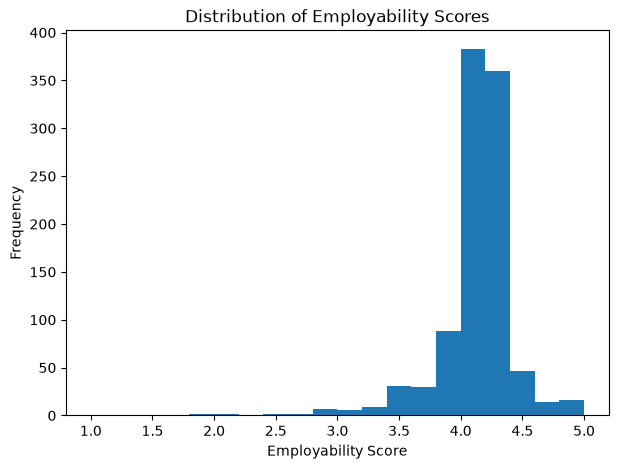

In [59]:
plt.figure(figsize=(7,5))


plt.hist(
    df["EVS_avg"],
    bins=20
)


plt.xlabel(
    "Employability Score"
)

plt.ylabel(
    "Frequency"
)

plt.title(
    "Distribution of Employability Scores"
)


plt.show()

Select Main Feature Set

In [60]:
FEATURES = combined_features

X = df_prepared[FEATURES]

y = df_prepared["EVS_avg"]

## Train-Test Split

The dataset was divided into training and testing sets.

80% of data was used for model training and 20% was reserved for evaluating model performance on unseen data.

In [61]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)


print(
    X_train.shape,
    X_test.shape
)

(800, 13) (200, 13)


Evaluation Function

In [62]:
def evaluate_model(
    model_name,
    y_true,
    y_pred
):

    return pd.DataFrame({

        "Model":[model_name],

        "R2":[
            r2_score(
                y_true,
                y_pred
            )
        ],

        "MAE":[
            mean_absolute_error(
                y_true,
                y_pred
            )
        ],

        "RMSE":[
            np.sqrt(
                mean_squared_error(
                    y_true,
                    y_pred
                )
            )
        ]

    })

## Baseline Model

A baseline model predicting the average Employability score is created as a reference point for evaluating machine learning improvements.

In [63]:
baseline_prediction = np.repeat(
    y_train.mean(),
    len(y_test)
)


baseline_results = evaluate_model(
    "Baseline",
    y_test,
    baseline_prediction
)


baseline_results

,Model,R2,MAE,RMSE
0,Baseline,-0.001145,0.239754,0.381958


Linear Regression

In [64]:
lr_model = Pipeline([

    (
        "scaler",
        StandardScaler()
    ),

    (
        "model",
        LinearRegression()
    )

])


lr_model.fit(
    X_train,
    y_train
)


lr_pred = lr_model.predict(
    X_test
)

## Random Forest Regression

Random Forest was selected because it can capture nonlinear relationships and provide feature importance information.

In [65]:
rf_model = RandomForestRegressor(
    n_estimators=200,
    random_state=42
)


rf_model.fit(
    X_train,
    y_train
)


rf_pred = rf_model.predict(
    X_test
)


rf_results = evaluate_model(
    "Random Forest",
    y_test,
    rf_pred
)


rf_results

,Model,R2,MAE,RMSE
0,Random Forest,0.473361,0.18307,0.277028


Support Vector Regression

In [66]:
svr_model = Pipeline([

    (
        "scaler",
        StandardScaler()
    ),

    (
        "model",
        SVR(
            kernel="rbf"
        )
    )

])


svr_model.fit(
    X_train,
    y_train
)


svr_pred = svr_model.predict(
    X_test
)

## XGBoost Regression

XGBoost is evaluated because it can model complex nonlinear relationships and often performs strongly on structured tabular datasets.

In [67]:
xgb_model = XGBRegressor(
    n_estimators=200,
    random_state=42
)


xgb_model.fit(
    X_train,
    y_train
)


xgb_pred = xgb_model.predict(
    X_test
)


xgb_results = evaluate_model(
    "XGBoost",
    y_test,
    xgb_pred
)


xgb_results

,Model,R2,MAE,RMSE
0,XGBoost,0.399107,0.190977,0.295914


Combine Results

In [68]:
model_results = pd.concat([

    baseline_results,

    lr_results,

    rf_results,

    svr_results,

    xgb_results

],
ignore_index=True)


model_results

,Model,R2,MAE,RMSE
0,Baseline,-0.001145,0.239754,0.381958
1,Linear Regression,0.524348,0.182995,0.263276
2,Random Forest,0.473361,0.183070,0.277028
3,SVR,0.297146,0.192609,0.320037
4,XGBoost,0.399107,0.190977,0.295914


Sort Best Model

In [69]:
model_results.sort_values(
    by="R2",
    ascending=False
)

,Model,R2,MAE,RMSE
1,Linear Regression,0.524348,0.182995,0.263276
2,Random Forest,0.473361,0.183070,0.277028
4,XGBoost,0.399107,0.190977,0.295914
3,SVR,0.297146,0.192609,0.320037
0,Baseline,-0.001145,0.239754,0.381958


Cross Validation

Feature Representation Experiment

In [70]:
def run_linear_model(X_data):

    X_train, X_test, y_train, y_test = train_test_split(
        X_data,
        y,
        test_size=0.2,
        random_state=42
    )


    model = Pipeline([

        (
            "scaler",
            StandardScaler()
        ),

        (
            "model",
            LinearRegression()
        )

    ])


    model.fit(
        X_train,
        y_train
    )


    prediction = model.predict(
        X_test
    )


    return r2_score(
        y_test,
        prediction
    )

In [71]:
feature_results = pd.DataFrame({

    "Feature_Set":[
        "Item_Level",
        "Construct_Level",
        "Combined"
    ],

    "R2":[

        run_linear_model(X_item),

        run_linear_model(X_construct),

        run_linear_model(X_combined)

    ]

})


feature_results

,Feature_Set,R2
0,Item_Level,0.524348
1,Construct_Level,0.545732
2,Combined,0.524348


## Cross Validation

Five-fold cross validation was applied to evaluate the stability and generalization performance of each machine learning model.

The R² score was calculated across five different data splits, and the average score was used for model comparison.

In [72]:
from sklearn.model_selection import KFold, cross_val_score


kf = KFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

In [73]:
lr_cv_scores = cross_val_score(
    lr_model,
    X,
    y,
    cv=kf,
    scoring="r2"
)

lr_cv_scores

array([0.5243479 , 0.29780572, 0.59200733, 0.62667271, 0.58232795])

In [74]:
rf_cv_scores = cross_val_score(
    rf_model,
    X,
    y,
    cv=kf,
    scoring="r2"
)

rf_cv_scores

array([0.4719592 , 0.30868511, 0.57807717, 0.69991165, 0.58256041])

In [75]:
svr_cv_scores = cross_val_score(
    svr_model,
    X,
    y,
    cv=kf,
    scoring="r2"
)

svr_cv_scores

array([0.30258668, 0.4229513 , 0.34334395, 0.4801726 , 0.5829844 ])

In [76]:
xgb_cv_scores = cross_val_score(
    xgb_model,
    X,
    y,
    cv=kf,
    scoring="r2"
)

xgb_cv_scores

array([ 0.39910738, -0.13375582,  0.60653272,  0.66812437,  0.52548644])

In [77]:
cv_results = pd.DataFrame({

    "Model":[
        "Linear Regression",
        "Random Forest",
        "SVR",
        "XGBoost"
    ],

    "Fold_1":[
        lr_cv_scores[0],
        rf_cv_scores[0],
        svr_cv_scores[0],
        xgb_cv_scores[0]
    ],

    "Fold_2":[
        lr_cv_scores[1],
        rf_cv_scores[1],
        svr_cv_scores[1],
        xgb_cv_scores[1]
    ],

    "Fold_3":[
        lr_cv_scores[2],
        rf_cv_scores[2],
        svr_cv_scores[2],
        xgb_cv_scores[2]
    ],

    "Fold_4":[
        lr_cv_scores[3],
        rf_cv_scores[3],
        svr_cv_scores[3],
        xgb_cv_scores[3]
    ],

    "Fold_5":[
        lr_cv_scores[4],
        rf_cv_scores[4],
        svr_cv_scores[4],
        xgb_cv_scores[4]
    ],

    "Mean_CV_R2":[
        lr_cv_scores.mean(),
        rf_cv_scores.mean(),
        svr_cv_scores.mean(),
        xgb_cv_scores.mean()
    ]

})


cv_results

,Model,Fold_1,Fold_2,Fold_3,Fold_4,Fold_5,Mean_CV_R2
0,Linear Regression,0.524348,0.297806,0.592007,0.626673,0.582328,0.524632
1,Random Forest,0.471959,0.308685,0.578077,0.699912,0.582560,0.528239
2,SVR,0.302587,0.422951,0.343344,0.480173,0.582984,0.426408
3,XGBoost,0.399107,-0.133756,0.606533,0.668124,0.525486,0.413099


In [78]:
final_comparison = pd.DataFrame({

    "Model":[
        "Linear Regression",
        "Random Forest",
        "SVR",
        "XGBoost"
    ],

    "CV_Mean_R2":[
        lr_cv_scores.mean(),
        rf_cv_scores.mean(),
        svr_cv_scores.mean(),
        xgb_cv_scores.mean()
    ]

})


final_comparison

,Model,CV_Mean_R2
0,Linear Regression,0.524632
1,Random Forest,0.528239
2,SVR,0.426408
3,XGBoost,0.413099


In [79]:
final_comparison.to_csv(
    RESULT_DIR /
    "Final_Model_Comparison.csv",
    index=False
)

Calculate Mean CV Scores

In [80]:
RESULT_DIR = (
    PROJECT_DIR
    /
    "reports"
    /
    "phase2"
    /
    "model_experiments"
)


RESULT_DIR.mkdir(
    parents=True,
    exist_ok=True
)

In [81]:
model_results.to_csv(
    RESULT_DIR /
    "Model_Performance_Comparison.csv",
    index=False
)

In [82]:
final_comparison.to_csv(
    RESULT_DIR /
    "Final_Model_Comparison.csv",
    index=False
)


feature_results.to_csv(
    RESULT_DIR /
    "Feature_Set_Comparison.csv",
    index=False
)

## Machine Learning Experiment Conclusion

Multiple machine learning models were evaluated using different feature representations.

Item-level, construct-level, and combined Competence features were compared.

Models were evaluated using R², MAE, RMSE, and cross-validation performance.

The best-performing approach will be selected for further hyperparameter optimization and explainability analysis.

In [83]:
feature_results

,Feature_Set,R2
0,Item_Level,0.524348
1,Construct_Level,0.545732
2,Combined,0.524348


In [84]:
baseline_results

,Model,R2,MAE,RMSE
0,Baseline,-0.001145,0.239754,0.381958


In [85]:
final_comparison

,Model,CV_Mean_R2
0,Linear Regression,0.524632
1,Random Forest,0.528239
2,SVR,0.426408
3,XGBoost,0.413099


In [86]:
cv_results

,Model,Fold_1,Fold_2,Fold_3,Fold_4,Fold_5,Mean_CV_R2
0,Linear Regression,0.524348,0.297806,0.592007,0.626673,0.582328,0.524632
1,Random Forest,0.471959,0.308685,0.578077,0.699912,0.582560,0.528239
2,SVR,0.302587,0.422951,0.343344,0.480173,0.582984,0.426408
3,XGBoost,0.399107,-0.133756,0.606533,0.668124,0.525486,0.413099


In [87]:
df["EVS_avg"].describe()

count    1000.000000
mean        4.101333
std         0.351081
min         1.000000
25%         4.000000
50%         4.166667
75%         4.333333
max         5.000000
Name: EVS_avg, dtype: float64

In [89]:
X.columns.tolist()

['C1',
 'C2',
 'C3',
 'C4',
 'C5',
 'C6',
 'C7',
 'C8',
 'C9',
 'C10',
 'LifeCareer_avg',
 'LearningInnovation_avg',
 'ITMedia_avg']

## Step 07 Conclusion

Machine learning experiments were conducted using multiple competence feature representations.

Construct-level features achieved the highest predictive performance among the evaluated representations.

Random Forest achieved the highest cross-validation R² score, while Linear Regression showed comparable performance.

Hyperparameter optimization will be performed in the next stage to improve model performance and identify the optimal model configuration.

Actual vs Predicted Values

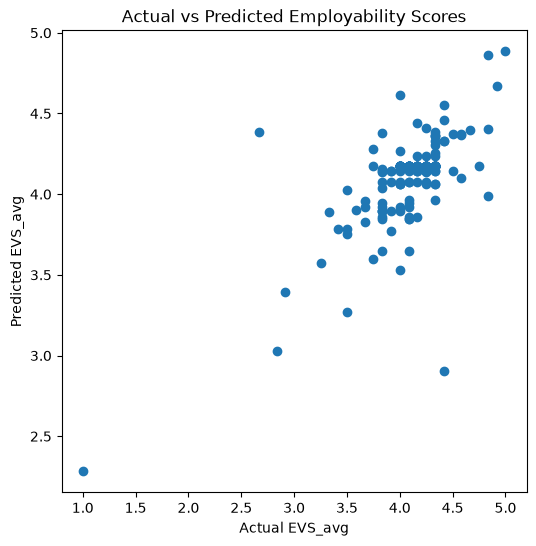

In [97]:
plt.figure(figsize=(6,6))

plt.scatter(
    y_test,
    rf_pred
)

plt.xlabel(
    "Actual EVS_avg"
)

plt.ylabel(
    "Predicted EVS_avg"
)

plt.title(
    "Actual vs Predicted Employability Scores"
)

plt.show()

Prediction Error Distribution

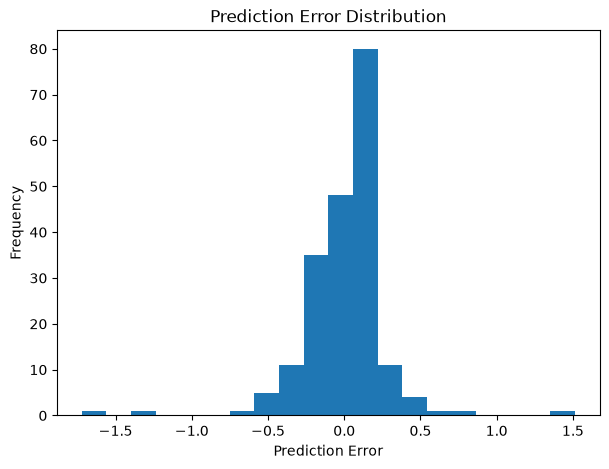

In [98]:
errors = y_test - rf_pred


plt.figure(figsize=(7,5))

plt.hist(
    errors,
    bins=20
)

plt.xlabel(
    "Prediction Error"
)

plt.ylabel(
    "Frequency"
)

plt.title(
    "Prediction Error Distribution"
)

plt.show()

In [99]:
prediction_check = pd.DataFrame({

    "Actual_EVScore": y_test,

    "Predicted_EVScore": rf_pred

})


prediction_check.head()

,Actual_EVScore,Predicted_EVScore
521,4.333333,4.173023
737,4.333333,4.173023
740,4.000000,4.173023
660,4.250000,4.173023
411,4.333333,4.173023


In [100]:
prediction_check["Error"] = (
    prediction_check["Actual_EVScore"]
    -
    prediction_check["Predicted_EVScore"]
)


prediction_check.head()

,Actual_EVScore,Predicted_EVScore,Error
521,4.333333,4.173023,0.160310
737,4.333333,4.173023,0.160310
740,4.000000,4.173023,-0.173023
660,4.250000,4.173023,0.076977
411,4.333333,4.173023,0.160310


Mean Absolute Percentage Error (MAPE)

In [101]:
from sklearn.metrics import mean_absolute_percentage_error


mape = mean_absolute_percentage_error(
    y_test,
    rf_pred
)


mape

0.05094274569338479

Feature Selection & Multicollinearity Check

In [104]:
construct_corr = df_prepared[
    construct_features
].corr()

construct_corr

,LifeCareer_avg,LearningInnovation_avg,ITMedia_avg
LifeCareer_avg,1.000000,0.680174,0.681089
LearningInnovation_avg,0.680174,1.000000,0.690881
ITMedia_avg,0.681089,0.690881,1.000000


In [106]:
import seaborn as sns
import matplotlib.pyplot as plt

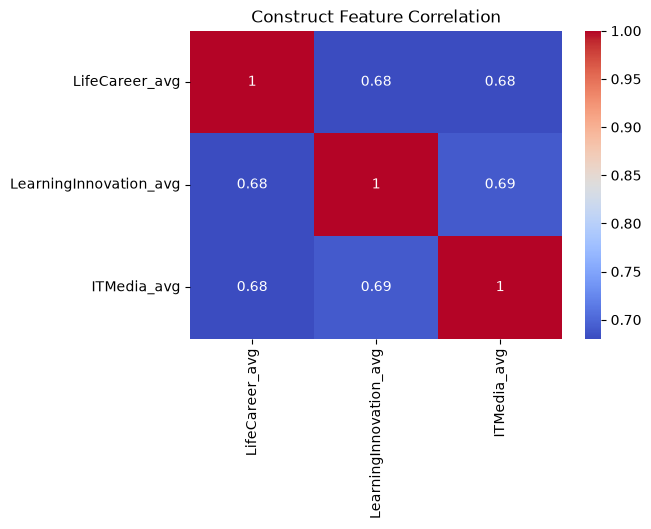

In [107]:
plt.figure(figsize=(6,4))

sns.heatmap(
    construct_corr,
    annot=True,
    cmap="coolwarm"
)

plt.title(
    "Construct Feature Correlation"
)

plt.show()

In [109]:
import pandas as pd
import statsmodels.api as sm
from statsmodels.stats.outliers_influence import variance_inflation_factor

construct_features = [
    "LifeCareer_avg",
    "LearningInnovation_avg",
    "ITMedia_avg"
]

X_vif = df_prepared[construct_features].copy()

# Add intercept/constant before calculating VIF
X_vif_const = sm.add_constant(X_vif)

vif_data = pd.DataFrame({
    "Feature": X_vif_const.columns,
    "VIF": [
        variance_inflation_factor(X_vif_const.values, i)
        for i in range(X_vif_const.shape[1])
    ]
})

# Remove the constant from the final table
vif_data = vif_data[
    vif_data["Feature"] != "const"
].reset_index(drop=True)

vif_data

,Feature,VIF
0,LifeCareer_avg,2.212152
1,LearningInnovation_avg,2.269008
2,ITMedia_avg,2.274283


## Multicollinearity Analysis

Multicollinearity among the selected competence constructs was assessed using the Variance Inflation Factor (VIF).

The VIF values were:

- Life & Career Skills: 2.21
- Learning & Innovation Skills: 2.27
- IT & Media Skills: 2.27

All VIF values were below the commonly accepted threshold of 5. Therefore, no serious multicollinearity problem was identified among the selected competence constructs, and all three constructs were retained for subsequent model development.

"I checked multicollinearity using VIF. All three values were around 2.2, which is below 5, so the selected competence constructs can be used together without serious multicollinearity."